In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
X = np.array([50, 60, 70, 80, 90], dtype=float)
y = np.array([150, 180, 210, 240, 270], dtype=float)


'''X represents the house size in square meters
y represents the house price in thousands.'''

'X represents the house size in square meters\ny represents the house price in thousands.'

In [2]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.001, n_iters=100):
        self.lr = learning_rate
        self.n_iters = n_iters
        self.theta_0 = 0.0
        self.theta_1 = 0.0
        self.sse_history = []
    def fit(self, X, y):
        n = len(X)
        for _ in range(self.n_iters):
            y_pred = self.theta_0 + self.theta_1 * X
            error = y_pred - y
            sse = np.sum(error ** 2)
            self.sse_history.append(sse)
            d_theta0 = (2 / n) * np.sum(error)
            d_theta1 = (2 / n) * np.sum(error * X)
            self.theta_0 -= self.lr * d_theta0
            self.theta_1 -= self.lr * d_theta1
    def predict(self, X):
        return self.theta_0 + self.theta_1 * X
    def plot_training(self, X, y):
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        axes[0].plot(self.sse_history, color="crimson")
        axes[0].set_title("SSE over Iterations")
        axes[0].set_xlabel("Iteration")
        axes[0].set_ylabel("SSE")

        axes[1].scatter(X, y, color="navy", label="Data points")
        x_line = np.linspace(X.min(), X.max(), 100)
        y_line = self.predict(x_line)
        axes[1].plot(x_line, y_line, color="darkorange", label="Regression line")
        axes[1].set_title("Regression Line vs Data")
        axes[1].set_xlabel("House size (m^2)")
        axes[1].set_ylabel("Price (thousands)")
        axes[1].legend()

        plt.tight_layout()
        plt.show()
 

In [3]:
print("=== Base run: lr=0.001, n_iters=100 ===")
model = LinearRegressionGD(learning_rate=0.001, n_iters=100)
model.fit(X, y)
print("theta_0 =", model.theta_0)
print("theta_1 =", model.theta_1)
print("Final SSE =", model.sse_history[-1])

=== Base run: lr=0.001, n_iters=100 ===
theta_0 = -1.0055957901462392e+95
theta_1 = -7.326427288635144e+96
Final SSE = 1.6170789775172399e+196


In [4]:
pred_70 = model.predict(np.array([70.0]))[0]
print("Predicted price for 70 m^2:", pred_70)

Predicted price for 70 m^2: -5.129504697834747e+98


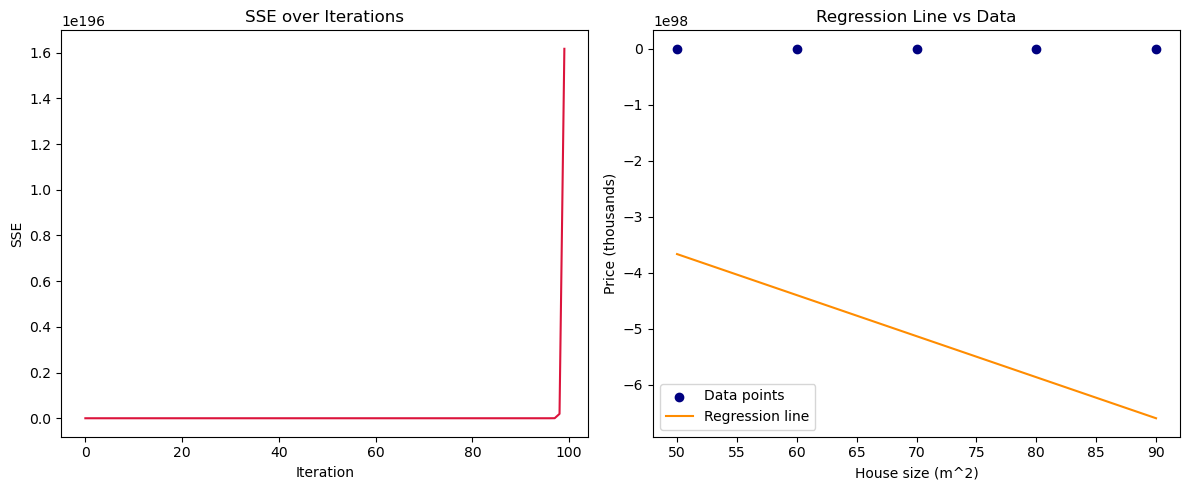

=== Experiment: very large learning rate (lr=0.01) ===
theta_0 = -1.1349322671141837e+199  theta_1 = -8.268728662168217e+200
Final SSE = inf
First 5 SSE values: [229500.0, 2342020408.2, 23900041831662.18, 2.4389710591561312e+17, 2.4889411781366236e+21]
=== Experiment: very small learning rate (lr=0.00001) ===
theta_0 = 0.04116492950170943  theta_1 = 2.9993713328364127
Final SSE = 0.00046041150816733306


C:\Users\DELL\AppData\Local\Temp\ipykernel_12608\276896590.py:13: RuntimeWarning: overflow encountered in square
  sse = np.sum(error ** 2)


In [6]:
model.plot_training(X, y)
 
print("=== Experiment: very large learning rate (lr=0.01) ===")
model_large = LinearRegressionGD(learning_rate=0.01, n_iters=100)
model_large.fit(X, y)
print("theta_0 =", model_large.theta_0, " theta_1 =", model_large.theta_1)
print("Final SSE =", model_large.sse_history[-1])
print("First 5 SSE values:", model_large.sse_history[:5])
print("=== Experiment: very small learning rate (lr=0.00001) ===")
model_small = LinearRegressionGD(learning_rate=0.00001, n_iters=100)
model_small.fit(X, y)
print("theta_0 =", model_small.theta_0, " theta_1 =", model_small.theta_1)
print("Final SSE =", model_small.sse_history[-1])